# Compare MSA generation

In [1]:
import collections
import glob
import itertools
import os
import re

import IPython.display as ipy_display
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pingouin as pg
import seaborn as sns
from matplotlib.axes import Axes
from matplotlib.ticker import PercentFormatter
from scipy import stats
from sklearn.metrics import roc_auc_score

In [2]:
sequences = pd.read_csv('../data/interim/sequences_sample_50.csv')
sequences['index'] = sequences['index'].apply(str)
sequences = sequences.set_index('index')
sequences['type'] = sequences['label'].map(lambda label: 'binder' if label else 'decoy')

In [3]:
with open('../data/interim/sequence_key.txt') as fh:
    sequence_key = {sequence: key for key, sequence in (line.split() for line in fh if line)}

In [4]:
full_sequences = pd.read_csv('../data/interim/sequences_full.csv')
full_sequences['id'] = full_sequences['id'].apply(str)
full_sequences = full_sequences.set_index('id')

## MSA generation time

In [5]:
msa_ids = set(full_sequences.melt(ignore_index=False)['value'].map(sequence_key).dropna().loc[sequences.index].tolist())

In [6]:
timings = []
for path in glob.glob('../data/benchmarks/msa-generation_*.tsv'):
    method_info = re.search(
        'msa-generation_(?P<msa_method>[a-zA-Z0-9]+)(?:_(?P<data_source>[a-zA-Z0-9]+))?_(?P<id>[a-zA-Z0-9]+).tsv',
        os.path.basename(path),
    ).groupdict()

    if method_info['msa_method'] not in ('af3', 'mmseqs2'):
        continue

    timing = pd.read_csv(path, delimiter='\t')

    for key, val in method_info.items():
        timing[key] = val

    timings.append(timing)

timings = pd.concat(timings).reset_index(drop=True)
timings = timings[timings['id'].isin(msa_ids)].copy()

In [7]:
def format_time(seconds: int) -> str:
    hours = seconds // 3600
    minutes = (seconds % 3600) // 60
    secs = seconds % 60
    parts = []
    if hours > 0:
        parts.append(f'{int(hours)} hours')

    if minutes > 0:
        parts.append(f'{int(minutes)} mins')

    if secs > 0 or not parts:
        parts.append(f'{int(secs)} secs')

    return ', '.join(parts)

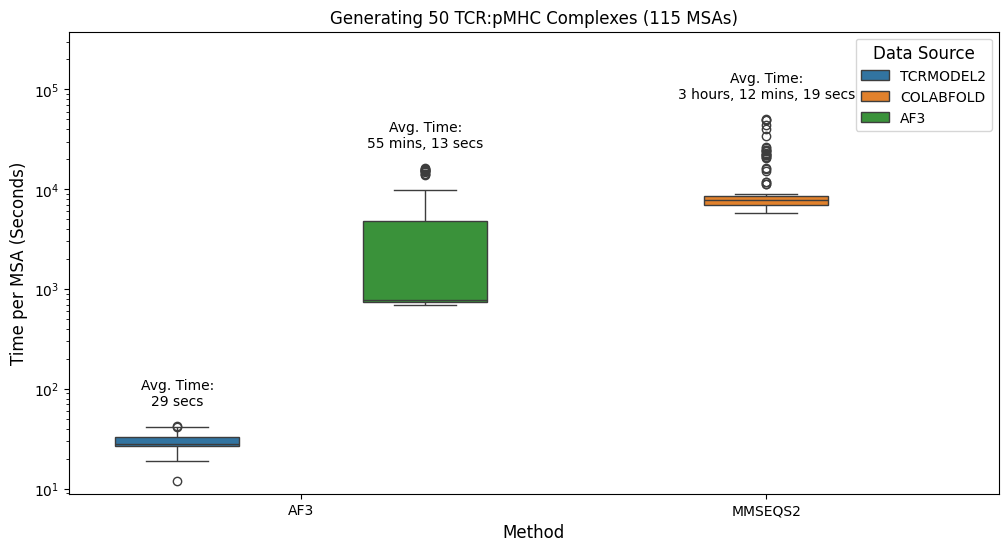

In [8]:
plt.figure(figsize=(12, 6))
plt.title('Generating 50 TCR:pMHC Complexes (115 MSAs)')

ax = sns.boxplot(timings, y='s', x='msa_method', hue='data_source')
ax.set(yscale='log')

ax.set_xlabel('Method', fontsize=12)
ax.set_ylabel('Time per MSA (Seconds)', fontsize=12)


groups = timings.groupby(['msa_method', 'data_source'])

x_labels = [tick_label.get_text() for tick_label in ax.get_xticklabels()]
handles, hue_labels = ax.get_legend_handles_labels()

n_x = len(x_labels)
n_hue = len(hue_labels)
positions = np.arange(n_x)

total_width = 0.8
box_width = total_width / n_hue

for i, x_label in enumerate(x_labels):
    for j, hue_label in enumerate(hue_labels):
        if (x_label, hue_label) not in groups.groups:
            continue

        group = groups.get_group((x_label, hue_label))
        x_pos = positions[i] - total_width / 2 + box_width * (j + 0.5)

        ax.text(
            x_pos,
            group['s'].max() * 1.5,
            f"Avg. Time:\n{format_time(group['s'].mean())}",
            ha='center',
            va='bottom',
        )

leg = ax.legend(title='Data Source', title_fontsize=12)
for text in leg.get_texts():
    text.set_text(text.get_text().upper())

ax.set_ylim(timings['s'].min() * 0.75, timings['s'].max() * 7.5)
ax.set_xticks(ax.get_xticks())
ax.set_xticklabels([label.get_text().upper() for label in ax.get_xticklabels()])

plt.savefig('../report/figures/msa_strategy_generation_time.svg')
plt.show()

## Antigen Specificity

In [9]:
af3_af3_confidences = pd.read_csv('../data/processed/confidence_scores_af3_af3_af3_50.csv')
af3_af3_confidences['name'] = af3_af3_confidences['name'].astype(str)
af3_af3_confidences['msa_method'] = 'af3'
af3_af3_confidences['data_source'] = 'af3'

af3_af3_confidences['top_rank'] = False
af3_af3_confidences.loc[af3_af3_confidences.groupby('name')['ranking_score'].idxmax(), 'top_rank'] = True

af3_tcrmodel2_confidences = pd.read_csv('../data/processed/confidence_scores_af3_af3_tcrmodel2_50.csv')
af3_tcrmodel2_confidences['name'] = af3_tcrmodel2_confidences['name'].astype(str)
af3_tcrmodel2_confidences['msa_method'] = 'af3'
af3_tcrmodel2_confidences['data_source'] = 'tcrmodel2'

af3_tcrmodel2_confidences['top_rank'] = False
af3_tcrmodel2_confidences.loc[af3_tcrmodel2_confidences.groupby('name')['ranking_score'].idxmax(), 'top_rank'] = True

mmseqs2_colabfold_confidences = pd.read_csv('../data/processed/confidence_scores_af3_mmseqs2_colabfold_50.csv')
mmseqs2_colabfold_confidences['name'] = mmseqs2_colabfold_confidences['name'].astype(str)
mmseqs2_colabfold_confidences['msa_method'] = 'mmseqs2'
mmseqs2_colabfold_confidences['data_source'] = 'colabfold'

mmseqs2_colabfold_confidences['top_rank'] = False
mmseqs2_colabfold_confidences.loc[
    mmseqs2_colabfold_confidences.groupby('name')['ranking_score'].idxmax(), 'top_rank'
] = True

confidences = pd.concat([af3_af3_confidences, af3_tcrmodel2_confidences, mmseqs2_colabfold_confidences])

In [10]:
confidences = confidences.merge(sequences, how='left', left_on='name', right_on='index')

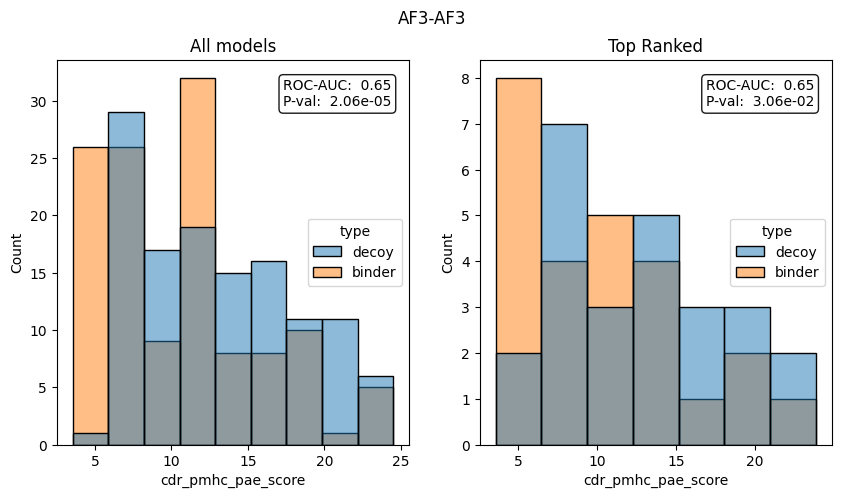

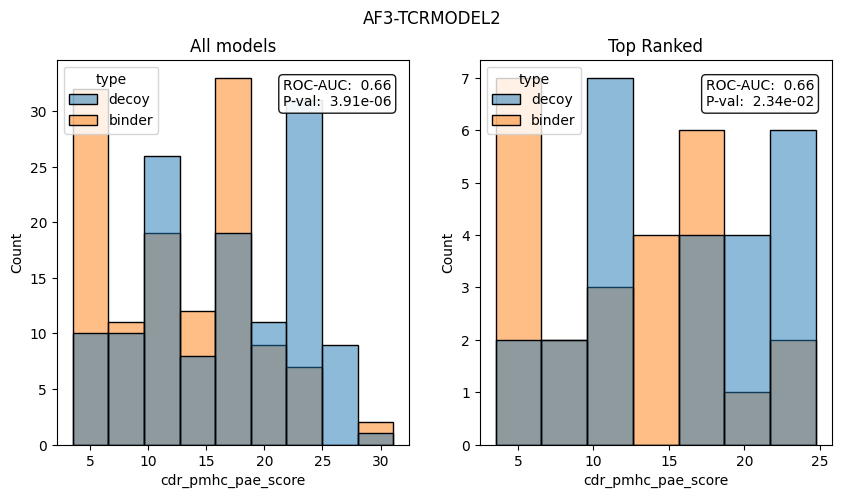

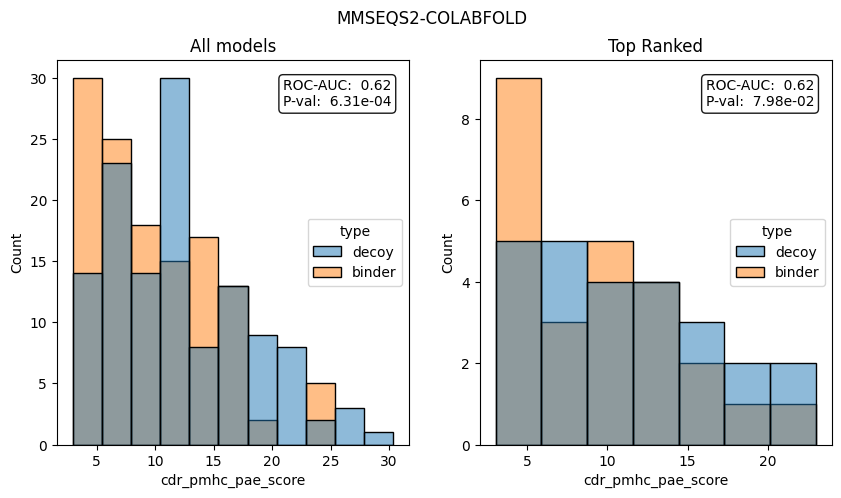

In [11]:
for name, group in confidences.groupby(['msa_method', 'data_source']):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 5))
    fig.suptitle('-'.join(name).upper())

    sns.histplot(group, x='cdr_pmhc_pae_score', hue='type', ax=ax1)
    ax1.set_title('All models')

    roc_auc = 1 - roc_auc_score(group['label'], group['cdr_pmhc_pae_score'])
    stat, p_val = stats.ranksums(
        group.query("type == 'binder'")['cdr_pmhc_pae_score'],
        group.query("type == 'decoy'")['cdr_pmhc_pae_score'],
        alternative='less',
    )
    ax1.text(
        0.95,
        0.95,
        f'ROC-AUC: {roc_auc: .2f}\nP-val: {p_val: .2e}',
        transform=ax1.transAxes,
        verticalalignment='top',
        horizontalalignment='right',
        bbox={'boxstyle': 'round', 'facecolor': 'white', 'alpha': 0.90},
    )

    group_top_rank = group.query('top_rank')
    sns.histplot(group_top_rank, x='cdr_pmhc_pae_score', hue='type', ax=ax2)
    ax2.set_title('Top Ranked')

    roc_auc_top_rank = 1 - roc_auc_score(group_top_rank['label'], group_top_rank['cdr_pmhc_pae_score'])
    stat_top_rank, p_val_top_rank = stats.ranksums(
        group_top_rank.query("type == 'binder'")['cdr_pmhc_pae_score'],
        group_top_rank.query("type == 'decoy'")['cdr_pmhc_pae_score'],
        alternative='less',
    )
    ax2.text(
        0.95,
        0.95,
        f'ROC-AUC: {roc_auc_top_rank: .2f}\nP-val: {p_val_top_rank: .2e}',
        transform=ax2.transAxes,
        verticalalignment='top',
        horizontalalignment='right',
        bbox={'boxstyle': 'round', 'facecolor': 'white', 'alpha': 0.90},
    )

In [12]:
NUM_SAMPLES = 15
SAMPLE_SIZE = 20

rng = np.random.default_rng(123)

structure_names = sorted(confidences['name'].unique())

roc_aucs = {
    'sample_number': [],
    'msa_method': [],
    'data_source': [],
    'roc_auc': [],
    'roc_auc_top': [],
}

for sample_number in range(1, NUM_SAMPLES + 1):
    sampled_structure_names = rng.choice(structure_names, SAMPLE_SIZE, replace=False)

    for (msa_method, data_source), group in confidences.groupby(['msa_method', 'data_source']):
        sample = group[group['name'].isin(sampled_structure_names)]
        sample_top_rank = sample.query('top_rank')

        roc_aucs['sample_number'].append(sample_number)
        roc_aucs['msa_method'].append(msa_method)
        roc_aucs['data_source'].append(data_source)
        roc_aucs['roc_auc'].append(1 - roc_auc_score(sample['label'], sample['cdr_pmhc_pae_score']))
        roc_aucs['roc_auc_top'].append(
            1 - roc_auc_score(sample_top_rank['label'], sample_top_rank['cdr_pmhc_pae_score'])
        )

roc_aucs = pd.DataFrame(roc_aucs)

In [13]:
roc_aucs = roc_aucs.melt(
    id_vars=['sample_number', 'msa_method', 'data_source'],
    value_vars=['roc_auc', 'roc_auc_top'],
    var_name='type',
    value_name='score',
)
roc_aucs['type'] = roc_aucs['type'].map({'roc_auc': 'all', 'roc_auc_top': 'top'})

In [14]:
roc_aucs['msa_method_data_source'] = roc_aucs['msa_method'] + '-' + roc_aucs['data_source']

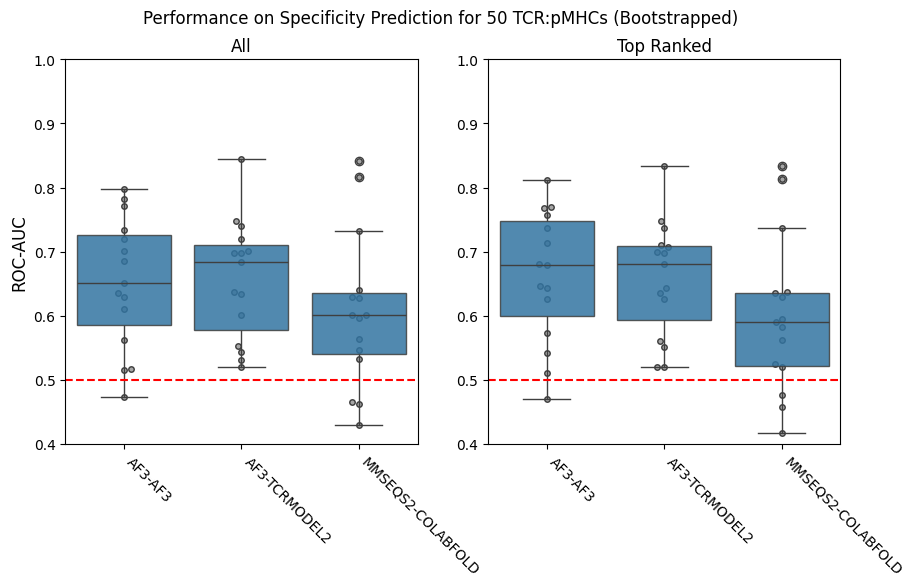

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(10, 5))

fig.suptitle('Performance on Specificity Prediction for 50 TCR:pMHCs (Bootstrapped)', fontsize=12)

for i, (ax, data, title) in enumerate(
    zip(axes, (roc_aucs.query("type == 'all'"), roc_aucs.query("type == 'top'")), ('All', 'Top Ranked'), strict=True)
):
    ax.set_title(title)

    sns.swarmplot(
        data,
        x='msa_method_data_source',
        y='score',
        color='grey',
        zorder=1,
        marker='o',
        size=4,
        edgecolor='black',
        linewidth=1,
        alpha=0.70,
        ax=ax,
    )
    sns.boxplot(data, x='msa_method_data_source', y='score', boxprops={'alpha': 0.85}, ax=ax)

    ax.axhline(0.5, color='red', linestyle='dashed')

    ax.set_ylim((0.40, 1.0))

    ax.set_ylabel('ROC-AUC' if i == 0 else '', fontsize=12)
    ax.set_xlabel('')

    ax.set_xticks(ax.get_xticks())
    ax.set_xticklabels([label.get_text().upper() for label in ax.get_xticklabels()], rotation=-45, ha='left')

plt.savefig('../report/figures/msa_strategy_specificity.svg', bbox_inches='tight')
plt.show()

In [16]:
def statistics_normal(data: pd.DataFrame, metric_name: str) -> tuple[pd.DataFrame, pd.DataFrame]:
    overall = pg.anova(data, dv=metric_name, between='msa_method_data_source')

    groups = list(data.groupby('msa_method_data_source')[metric_name])

    significance_level = 0.05 / len(groups)

    post_hoc = collections.defaultdict(list)
    for (group1_name, group1), (group2_name, group2) in itertools.combinations(groups, 2):
        stat, p_val = stats.ttest_ind(group1, group2, alternative='two-sided')

        post_hoc['group1'].append(group1_name)
        post_hoc['group2'].append(group2_name)
        post_hoc['stat'].append(stat)
        post_hoc['p_val'].append(p_val)
        post_hoc['signficant'].append(p_val < significance_level)

    return overall, pd.DataFrame(post_hoc)

In [17]:
for data, title in zip(
    (roc_aucs.query("type == 'all'"), roc_aucs.query("type == 'top'")), ('All', 'Top Ranked'), strict=True
):
    print(title)
    overall, post_hoc = statistics_normal(data, 'score')

    ipy_display.display(overall)
    ipy_display.display(post_hoc)

    print()

All


,Source,ddof1,ddof2,F,p-unc,np2
0,msa_method_data_source,2,42,1.06371,0.354288,0.048211


,group1,group2,stat,p_val,signficant
0,af3-af3,af3-tcrmodel2,-0.120147,0.905225,False
1,af3-af3,mmseqs2-colabfold,1.143119,0.262669,False
2,af3-tcrmodel2,mmseqs2-colabfold,1.295350,0.205778,False



Top Ranked


,Source,ddof1,ddof2,F,p-unc,np2
0,msa_method_data_source,2,42,1.572773,0.219443,0.069676


,group1,group2,stat,p_val,signficant
0,af3-af3,af3-tcrmodel2,0.110619,0.912707,False
1,af3-af3,mmseqs2-colabfold,1.488529,0.147789,False
2,af3-tcrmodel2,mmseqs2-colabfold,1.464477,0.154202,False


## DockQ

In [18]:
CAPRI_ACCEPTABLE_CUTOFF = 0.23
CAPRI_MEDIUM_CUTOFF = 0.49
CAPRI_HIGH_CUTOFF = 0.80


def get_capri_classification(dockq: float) -> str:
    if dockq < CAPRI_ACCEPTABLE_CUTOFF:
        return 'Incorrect'

    if CAPRI_ACCEPTABLE_CUTOFF <= dockq < CAPRI_MEDIUM_CUTOFF:
        return 'Acceptable'

    if CAPRI_MEDIUM_CUTOFF <= dockq < CAPRI_HIGH_CUTOFF:
        return 'Medium'

    return 'High'

In [19]:
af3_af3_dockq_scores = pd.read_csv('../data/processed/predicted_af3_af3_af3_dockq_benchmark.csv')
af3_af3_dockq_scores['name'] = af3_af3_dockq_scores['name'].astype(str)
af3_af3_dockq_scores['msa_method'] = 'af3'
af3_af3_dockq_scores['data_source'] = 'af3'

af3_af3_confidence_scores_benchmark = pd.read_csv('../data/interim/confidence_scores_af3_af3_af3_benchmark.csv')
af3_af3_confidence_scores_benchmark['top_rank'] = False
af3_af3_confidence_scores_benchmark.loc[
    af3_af3_confidence_scores_benchmark.groupby('name')['ranking_score'].idxmax(), 'top_rank'
] = True

af3_af3_dockq_scores = af3_af3_dockq_scores.merge(
    af3_af3_confidence_scores_benchmark, how='inner', on=['name', 'seed', 'sample']
)

af3_tcrmodel2_dockq_scores = pd.read_csv('../data/processed/predicted_af3_af3_tcrmodel2_dockq_benchmark.csv')
af3_tcrmodel2_dockq_scores['name'] = af3_tcrmodel2_dockq_scores['name'].astype(str)
af3_tcrmodel2_dockq_scores['msa_method'] = 'af3'
af3_tcrmodel2_dockq_scores['data_source'] = 'tcrmodel2'

af3_tcrmodel2_confidence_scores_benchmark = pd.read_csv(
    '../data/interim/confidence_scores_af3_af3_tcrmodel2_benchmark.csv'
)
af3_tcrmodel2_confidence_scores_benchmark['top_rank'] = False
af3_tcrmodel2_confidence_scores_benchmark.loc[
    af3_tcrmodel2_confidence_scores_benchmark.groupby('name')['ranking_score'].idxmax(), 'top_rank'
] = True

af3_tcrmodel2_dockq_scores = af3_tcrmodel2_dockq_scores.merge(
    af3_tcrmodel2_confidence_scores_benchmark, how='inner', on=['name', 'seed', 'sample']
)

dockq_scores = pd.concat([af3_af3_dockq_scores, af3_tcrmodel2_dockq_scores]).reset_index(drop=True)

In [20]:
dockq_scores['capri_classification'] = dockq_scores['DockQ'].map(get_capri_classification)

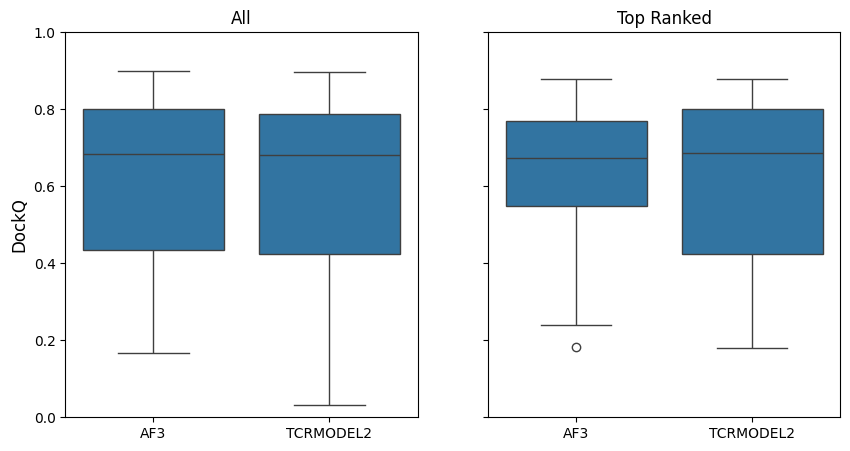

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(10, 5))

axes[0].set_title('All')
sns.boxplot(dockq_scores.sort_values('data_source'), y='DockQ', x='data_source', ax=axes[0])

axes[0].set_ylim(0, 1)
axes[0].set_ylabel(axes[0].get_ylabel(), fontsize=12)
axes[0].set_xticks(axes[0].get_xticks())
axes[0].set_xticklabels([label.get_text().upper() for label in axes[0].get_xticklabels()])
axes[0].set_xlabel('')

axes[1].set_title('Top Ranked')
sns.boxplot(dockq_scores.sort_values('data_source').query('top_rank'), y='DockQ', x='data_source', ax=axes[1])

axes[1].set_ylim(0, 1)
axes[1].set_ylabel('')
axes[1].set_yticklabels([])
axes[1].set_xticks(axes[1].get_xticks())
axes[1].set_xticklabels([label.get_text().upper() for label in axes[1].get_xticklabels()])
axes[1].set_xlabel('')

plt.savefig('../report/figures/msa_strategy_dockq_boxplot.svg')
plt.show()

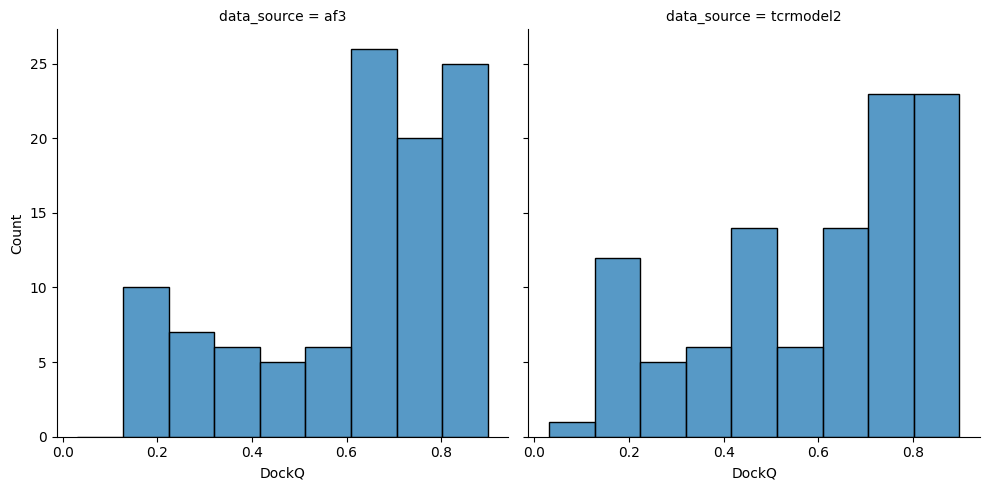

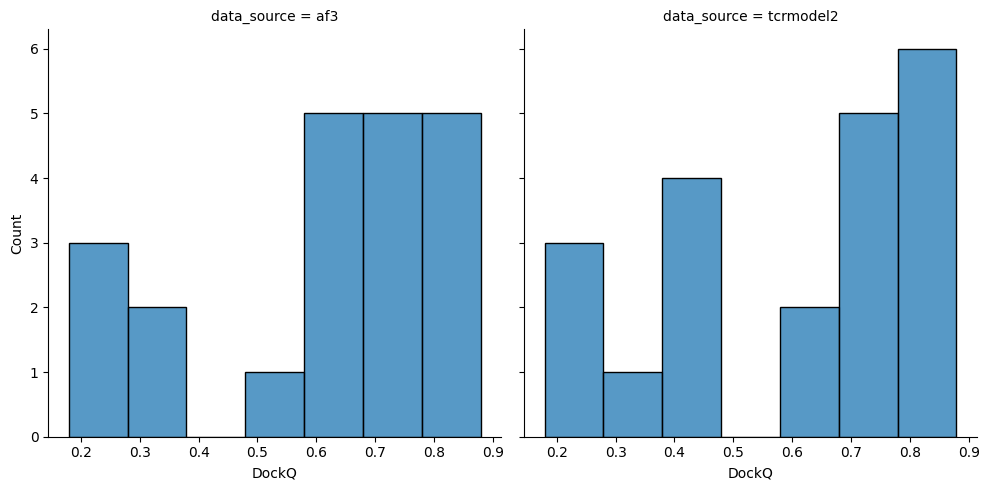

In [22]:
sns.displot(dockq_scores.sort_values('data_source'), x='DockQ', col='data_source', kind='hist')
plt.show()
sns.displot(dockq_scores.query('top_rank').sort_values('data_source'), x='DockQ', col='data_source', kind='hist')
plt.show()

In [23]:
def get_significance(dockq_scores: pd.DataFrame) -> tuple[float, float]:
    (_, group_af3), (_, group_tcrmodel2) = (
        dockq_scores.sort_values(['data_source', 'name', 'seed', 'sample'])
        .set_index(['name', 'seed', 'sample'])
        .groupby('data_source')
    )

    comparison = group_af3.merge(
        group_tcrmodel2, how='inner', left_index=True, right_index=True, suffixes=('_af3', '_tcrmodel2')
    )
    stat, p_val = stats.wilcoxon(comparison['DockQ_af3'].fillna(0.0), comparison['DockQ_tcrmodel2'].fillna(0.0))

    return stat, p_val


print('All p-value:', get_significance(dockq_scores)[1])
print('Top Ranked p-value:', get_significance(dockq_scores.query('top_rank'))[1])

All p-value: 0.17274406431673273
Top Ranked p-value: 0.5185546875


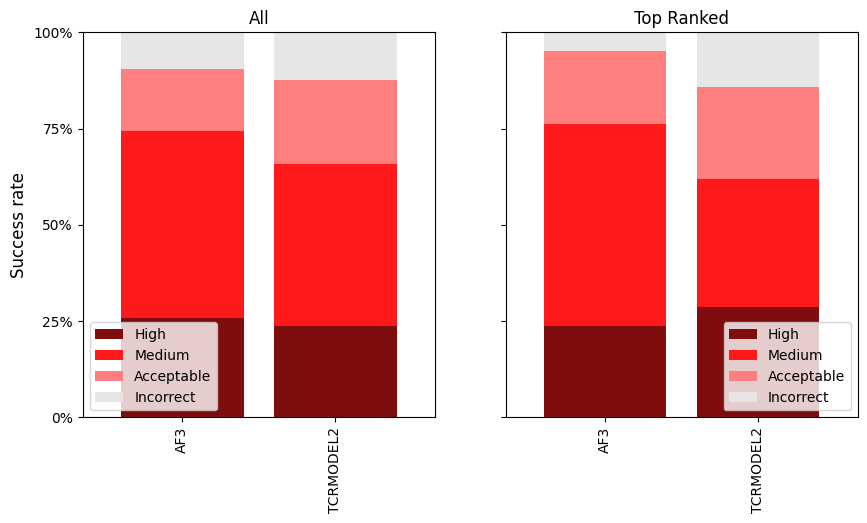

In [24]:
def plot_capri_classification(dockq_scores: pd.DataFrame, ax: Axes | None = None) -> Axes:
    capri_classification = (
        dockq_scores.groupby('data_source')['capri_classification'].value_counts(normalize=True) * 100
    )
    capri_classification.name = 'percent'
    capri_classification = capri_classification.reset_index()
    capri_classification = capri_classification.pivot_table(
        index='data_source', columns='capri_classification', values='percent'
    )

    order = ['High', 'Medium', 'Acceptable', 'Incorrect']
    colours = {
        'High': '#7f0d0d',
        'Medium': '#ff1a1a',
        'Acceptable': '#ff7f7f',
        'Incorrect': '#e6e6e6',
    }

    plot_ax = capri_classification.reindex(columns=order, fill_value=0).plot(
        kind='bar', stacked=True, color=[colours[col_name] for col_name in order], width=0.8, edgecolor='none', ax=ax
    )

    plot_ax.set_ylim(0, 100)
    plot_ax.yaxis.set_major_formatter(PercentFormatter(xmax=100))
    plot_ax.set_ylabel('Success rate', fontsize=12)
    plot_ax.set_yticks([0, 25, 50, 75, 100])
    plot_ax.set_xlabel('')
    plot_ax.set_xticklabels([label.get_text().upper() for label in plot_ax.get_xticklabels()])
    plot_ax.legend(title='')

    return plot_ax


fig, axes = plt.subplots(1, 2, figsize=(10, 5))

axes[0].set_title('All')
plot_capri_classification(dockq_scores, ax=axes[0])

axes[1].set_title('Top Ranked')
plot_capri_classification(dockq_scores.query('top_rank'), ax=axes[1])

axes[1].set_yticklabels([])
axes[1].set_ylabel('')

plt.savefig('../report/figures/msa_strategy_dockq_capri.svg', bbox_inches='tight')
plt.show()